# P4 · Level 2: neural network (PyTorch, as in Recitation 7)
**Owner: Member A** · CMPS 261 Project 4.1 · Kepler Objects of Interest

Plan:
1. Inputs: the **scaled** pipeline (median imputation + "was missing" columns → StandardScaler), fitted on **train rows only**.
2. Network: `Linear → ReLU → (Dropout)` per hidden layer, then `Linear → Sigmoid`. `BCELoss`, AdamW (lr 1e-3), batch 64, up to 300 epochs, **early stopping** on validation loss (patience 20), best weights restored.
3. Compare 5 settings and choose the one with the **lowest validation loss** (R7).
4. Plot training vs validation loss (chosen setting vs (128, 64) without regularisation).
5. Run the chosen setting with 3 seeds (randomness of initialisation).
6. Save `models/neural_net.pt` and `results/preds_NeuralNet.csv`.

F1 here uses threshold 0.5. The threshold itself is tuned on validation in P5. The test set is only predicted and saved, never looked at.

## 0. Setup

In [1]:
import os, sys
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/kepler-koi-classification/notebooks")

import json, time, copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score, precision_score, recall_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))            # so `import features` finds features.py in the repo root
(ROOT / "models").mkdir(exist_ok=True)
(ROOT / "results").mkdir(exist_ok=True)

SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Repo root:", ROOT, "| device:", DEVICE)

Repo root: c:\Users\Administrator\kepler-koi-classification | device: cpu


## 1. Data and features
`koi_split.csv` comes from P1. The feature list, the engineered features and the scaled pipeline come from **B's `features.py`** (P2), so the network gets exactly the same inputs as the classical models. `get_X()` adds the 3 engineered features and the log columns and returns the 21 features in a fixed order.

In [2]:
from features import FEATURES, get_X, make_scaled_pipeline

df = pd.read_csv(ROOT / "data" / "processed" / "koi_split.csv", low_memory=False)
print(df["split"].value_counts().to_dict())

is_tr, is_va, is_te = (df["split"] == s for s in ["train", "val", "test"])

prep = make_scaled_pipeline()                      # imputer(median, indicator) -> StandardScaler
X_tr = prep.fit_transform(get_X(df[is_tr]))        # statistics learned on train rows only
X_va = prep.transform(get_X(df[is_va]))
X_te = prep.transform(get_X(df[is_te]))
y_tr, y_va, y_te = (df.loc[m, "label"].to_numpy() for m in [is_tr, is_va, is_te])
print(f"Inputs: {X_tr.shape[1]} columns ({len(FEATURES)} features + 'was missing' indicators)")
print("train / val / test rows:", len(y_tr), len(y_va), len(y_te))

{'train': 4519, 'test': 1546, 'val': 1522}
Inputs: 40 columns (21 features + 'was missing' indicators)
train / val / test rows: 4519 1522 1546


In [3]:
def to_tensor(X, y=None):
    X = torch.tensor(X, dtype=torch.float32)
    if y is None:
        return X
    return X, torch.tensor(y, dtype=torch.float32).view(-1, 1)   # labels float, shape [n, 1]

Xtr_t, ytr_t = to_tensor(X_tr, y_tr)
Xva_t, yva_t = to_tensor(X_va, y_va)
Xte_t = to_tensor(X_te)

## 2. Network and training loop

In [4]:
class MLP(nn.Module):
    def __init__(self, n_in, hidden, dropout=0.0):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers += [nn.Linear(prev, 1), nn.Sigmoid()]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def predict_proba(model, X):
    model.eval()
    with torch.no_grad():
        return model(X.to(DEVICE)).cpu().numpy().ravel()


def train_mlp(hidden, dropout=0.0, weight_decay=0.0, seed=SEED,
              lr=1e-3, batch_size=64, max_epochs=300, patience=20):
    torch.manual_seed(seed); np.random.seed(seed)
    model = MLP(X_tr.shape[1], hidden, dropout).to(DEVICE)
    # AdamW's default weight_decay is 0.01, so set it explicitly (0 = no weight decay)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCELoss()
    loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    hist = {"train_loss": [], "val_loss": []}
    best_val, best_state, best_epoch, wait = np.inf, None, 0, 0
    t0 = time.time()
    for epoch in range(1, max_epochs + 1):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()

        model.eval()
        with torch.no_grad():
            tr_loss = loss_fn(model(Xtr_t.to(DEVICE)), ytr_t.to(DEVICE)).item()
            va_loss = loss_fn(model(Xva_t.to(DEVICE)), yva_t.to(DEVICE)).item()
        hist["train_loss"].append(tr_loss); hist["val_loss"].append(va_loss)

        if va_loss < best_val:                       # early stopping on validation loss
            best_val, best_epoch, wait = va_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)                # restore the best weights
    train_time = time.time() - t0

    p_tr, p_va = predict_proba(model, Xtr_t), predict_proba(model, Xva_t)
    result = {
        "params":     sum(p.numel() for p in model.parameters()),
        "best_epoch": best_epoch,
        "epochs_run": len(hist["val_loss"]),
        "train_F1":   f1_score(y_tr, p_tr >= 0.5),
        "val_loss":   best_val,
        "val_F1":     f1_score(y_va, p_va >= 0.5),
        "train_time_s": train_time,
    }
    return model, hist, result

## 3. Compare 5 settings (choose the lowest validation loss)

In [5]:
SETTINGS = {
    "(32)":                       dict(hidden=(32,)),
    "(64, 32)":                   dict(hidden=(64, 32)),
    "(128, 64)":                  dict(hidden=(128, 64)),
    "(128, 64) + dropout":        dict(hidden=(128, 64), dropout=0.3),
    "(128, 64) + dropout + wd":   dict(hidden=(128, 64), dropout=0.3, weight_decay=0.01),
}

runs, rows = {}, []
for name, cfg in SETTINGS.items():
    model, hist, res = train_mlp(**cfg)
    runs[name] = (model, hist, cfg)
    rows.append({"setting": name, **res})
    print(f"{name:<26} best epoch {res['best_epoch']:>3}   val loss {res['val_loss']:.4f}   val F1 {res['val_F1']:.3f}")

table = pd.DataFrame(rows).set_index("setting")
table["train_F1"] = table["train_F1"].round(3); table["val_F1"] = table["val_F1"].round(3)
table["val_loss"] = table["val_loss"].round(4); table["train_time_s"] = table["train_time_s"].round(1)
CHOSEN = table["val_loss"].idxmin()
print("\nChosen setting (lowest validation loss):", CHOSEN)
table

(32)                       best epoch  49   val loss 0.1158   val F1 0.949
(64, 32)                   best epoch  19   val loss 0.1158   val F1 0.945
(128, 64)                  best epoch  13   val loss 0.1113   val F1 0.950
(128, 64) + dropout        best epoch  20   val loss 0.1150   val F1 0.945
(128, 64) + dropout + wd   best epoch  20   val loss 0.1145   val F1 0.946

Chosen setting (lowest validation loss): (128, 64)


,params,best_epoch,epochs_run,train_F1,val_loss,val_F1,train_time_s
setting,,,,,,,
(32),1345,49,69,0.968,0.1158,0.949,6.5
"(64, 32)",4737,19,39,0.970,0.1158,0.945,4.3
"(128, 64)",13569,13,33,0.970,0.1113,0.950,3.8
"(128, 64) + dropout",13569,20,40,0.971,0.1150,0.945,5.3
"(128, 64) + dropout + wd",13569,20,40,0.972,0.1145,0.946,5.7


## 4. Training vs validation loss
Left: the chosen setting. Right: (128, 64) without regularisation (or, if that is the chosen one, the version with dropout + weight decay). If the validation loss turns upward while the training loss keeps falling, the network has started memorising the training data (overfitting). The dotted line marks the epoch whose weights were kept.

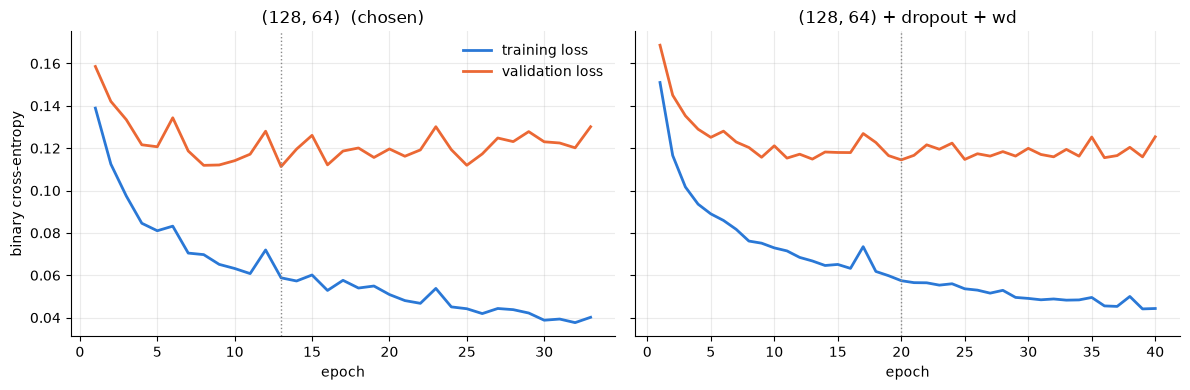

In [6]:
TRAIN_COLOR, VAL_COLOR = "#2a78d6", "#eb6834"
# chosen setting vs (128, 64) without regularisation; if those are the same, compare with the regularised one
panels = [CHOSEN, "(128, 64)"] if CHOSEN != "(128, 64)" else ["(128, 64)", "(128, 64) + dropout + wd"]
fig, axes = plt.subplots(1, len(panels), figsize=(6 * len(panels), 4), sharey=True, squeeze=False)
for ax, name in zip(axes[0], panels):
    hist = runs[name][1]
    epochs = range(1, len(hist["train_loss"]) + 1)
    ax.plot(epochs, hist["train_loss"], color=TRAIN_COLOR, lw=2, label="training loss")
    ax.plot(epochs, hist["val_loss"],   color=VAL_COLOR,   lw=2, label="validation loss")
    best = int(np.argmin(hist["val_loss"])) + 1
    ax.axvline(best, color="#888888", lw=1, ls=":")
    ax.set_title(f"{name}{'  (chosen)' if name == CHOSEN else ''}")
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.25)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0][0].set_ylabel("binary cross-entropy")
axes[0][0].legend(frameon=False)
plt.tight_layout()
plt.savefig(ROOT / "results" / "nn_loss_curves.png", dpi=150)
plt.show()

## 5. Randomness of initialisation (3 seeds)

In [7]:
seed_rows = []
for s in [0, 1, 2]:
    _, _, res = train_mlp(**SETTINGS[CHOSEN], seed=s)
    seed_rows.append({"seed": s, "best_epoch": res["best_epoch"],
                      "val_loss": round(res["val_loss"], 4), "val_F1": round(res["val_F1"], 3)})
seeds = pd.DataFrame(seed_rows).set_index("seed")
print(f"Validation F1 over 3 seeds: {seeds['val_F1'].mean():.3f} ± {seeds['val_F1'].std():.3f}")
seeds

Validation F1 over 3 seeds: 0.947 ± 0.003


,best_epoch,val_loss,val_F1
seed,,,
0,13,0.1141,0.948
1,12,0.1123,0.943
2,19,0.1123,0.949


## 6. Save the model and the predictions
The model trained with `SEED = 42` is the one kept. `preds_NeuralNet.csv` has `kepoi_name, label, split, p` for validation and test rows (shared format from the plan); P5 chooses the threshold on the validation rows and evaluates once on test.

In [8]:
final_model, _, final_cfg = runs[CHOSEN]
torch.save(final_model.state_dict(), ROOT / "models" / "neural_net.pt")
joblib.dump(prep, ROOT / "models" / "neural_net_preprocess.joblib")      # the fitted scaled pipeline
(ROOT / "models" / "neural_net_config.json").write_text(json.dumps({
    "setting": CHOSEN, "n_inputs": X_tr.shape[1], "hidden": list(final_cfg["hidden"]),
    "dropout": final_cfg.get("dropout", 0.0), "weight_decay": final_cfg.get("weight_decay", 0.0),
    "features": FEATURES, "seed": SEED}, indent=2))

preds = pd.concat([
    df.loc[is_va, ["kepoi_name", "label", "split"]].assign(p=predict_proba(final_model, Xva_t)),
    df.loc[is_te, ["kepoi_name", "label", "split"]].assign(p=predict_proba(final_model, Xte_t)),
])
preds.to_csv(ROOT / "results" / "preds_NeuralNet.csv", index=False)
print("Saved models/neural_net.pt, models/neural_net_preprocess.joblib, models/neural_net_config.json")
print(f"Saved results/preds_NeuralNet.csv ({len(preds)} rows: val + test)")
table.to_csv(ROOT / "results" / "nn_settings.csv")
print("Next: commit and push → message 'P4: neural network'")

Saved models/neural_net.pt, models/neural_net_preprocess.joblib, models/neural_net_config.json
Saved results/preds_NeuralNet.csv (3068 rows: val + test)
Next: commit and push → message 'P4: neural network'


## Explain (for the report / professor)
*"Early stopping stops when the validation loss stops improving, before the network memorises the training data; dropout and weight decay are regularisation."*

To load the saved model later (P5 / P7):
```python
cfg = json.loads((ROOT / "models" / "neural_net_config.json").read_text())
model = MLP(cfg["n_inputs"], cfg["hidden"], cfg["dropout"])
model.load_state_dict(torch.load(ROOT / "models" / "neural_net.pt"))
prep = joblib.load(ROOT / "models" / "neural_net_preprocess.joblib")
```